# 09. Equipamentos e serviços

Para diagnosticar e acompanhar o câncer de mama, não bastam médicos: são necessários equipamentos de imagem e hospitais habilitados. Este caderno mostra quantos equipamentos existem no país, quantos estão de fato em uso, quantos estão disponíveis para o SUS e onde estão. Depois faz o mesmo com os serviços oncológicos (UNACON e CACON), a radioterapia e a atenção primária.

A fonte é o Cadastro Nacional de Estabelecimentos de Saúde (CNES), que lista cada aparelho de cada estabelecimento do país, indicando a quantidade existente, a quantidade em uso e se ele atende pelo SUS. Usamos a competência de setembro de 2025, a mais recente, e mais três anos (2013, 2018 e 2023) para ver a evolução.

## Para que serve cada equipamento

| Equipamento | Papel no câncer de mama |
|---|---|
| Mamógrafo | Rastreamento e diagnóstico; é o exame que encontra tumores ainda não palpáveis |
| Ultrassom | Complementa a mamografia, principalmente em mamas densas e em mulheres jovens; guia biópsias |
| Tomógrafo | Estadiamento (procura metástases no pulmão, fígado e ossos) e planejamento da radioterapia |
| Ressonância magnética | Avaliação da extensão do tumor, rastreamento de mulheres de alto risco |
| Medicina nuclear (gama câmara) | Cintilografia óssea para procurar metástases e localização do linfonodo sentinela |
| PET/CT | Estadiamento de casos avançados e avaliação de resposta ao tratamento |

Os aparelhos de radioterapia (aceleradores lineares) só passaram a ter código próprio no CNES em agosto de 2025, e ainda não aparecem nos arquivos públicos. Por isso a radioterapia é analisada pelas habilitações dos serviços e pela APAC de radioterapia (caderno 10).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.config import FONTE_CNES
from mama.analises import base, equipamentos as eq, rede, deslocamento as desl

pd.set_option("display.max_columns", 20)
ORDEM_EQ = list(c.EQUIPAMENTOS)

## Quantos equipamentos existem no Brasil

A tabela mostra, para cada tipo de equipamento, a quantidade existente, a quantidade em uso e a quantidade disponível ao SUS, além de duas taxas por 100 mil habitantes. A diferença entre "existentes" e "em uso" são aparelhos parados (quebrados, sem técnico ou desativados).

In [2]:
br = eq.brasil().set_index("equipamento").reindex(ORDEM_EQ)
base.salvar_tabela(br, "09_equipamentos_brasil", index=True)
br[["qt_existente", "qt_em_uso", "qt_sus", "em_uso_por_100mil_hab", "em_uso_sus_por_100mil_hab", "pct_disponivel_sus"]]

,qt_existente,qt_em_uso,qt_sus,em_uso_por_100mil_hab,em_uso_sus_por_100mil_hab,pct_disponivel_sus
equipamento,,,,,,
Mamógrafo,7025,6775,3443,3.17,1.55,49.0
Tomógrafo,7488,7270,3755,3.41,1.71,50.1
Ressonância magnética,3748,3660,1791,1.71,0.82,47.8
Ultrassom,59983,57699,27224,27.04,12.28,45.4
PET/CT,157,155,86,0.07,0.04,54.8
Gama câmara (medicina nuclear),895,856,467,0.4,0.21,52.2


O Brasil tem cerca de 7 mil mamógrafos e 7,5 mil tomógrafos. A informação mais importante está na última coluna: só metade desses aparelhos está disponível para o SUS (49% dos mamógrafos e 50% dos tomógrafos). Como cerca de três quartos da população depende exclusivamente do SUS, isso significa que a maioria das pessoas disputa a menor metade dos equipamentos. Por habitante, a rede pública tem 1,6 mamógrafo e 1,7 tomógrafo em uso para cada 100 mil pessoas, menos da metade do total do país.

## Equipamentos em uso por região

O mapa de calor mostra os equipamentos em uso por 100 mil habitantes em cada região. Os valores de cada coluna devem ser comparados entre si (de cima para baixo), porque os tipos de aparelho têm quantidades muito diferentes.

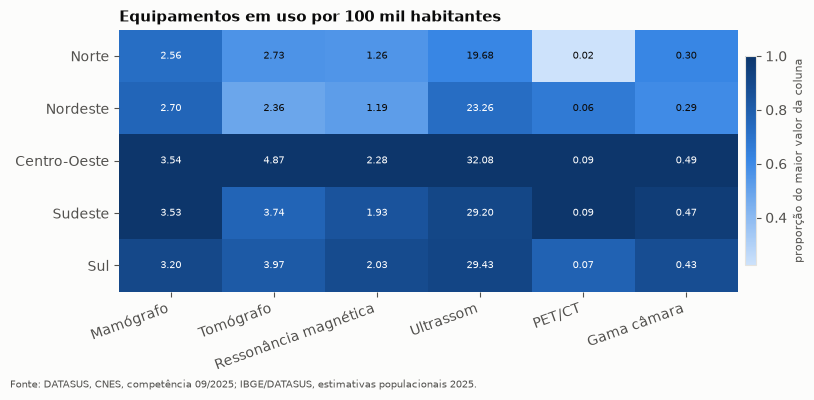

equipamento,Mamógrafo,Tomógrafo,Ressonância magnética,Ultrassom,PET/CT,Gama câmara (medicina nuclear)
regiao,,,,,,
Norte,2.56,2.73,1.26,19.68,0.02,0.3
Nordeste,2.7,2.36,1.19,23.26,0.06,0.29
Centro-Oeste,3.54,4.87,2.28,32.08,0.09,0.49
Sudeste,3.53,3.74,1.93,29.2,0.09,0.47
Sul,3.2,3.97,2.03,29.43,0.07,0.43


equipamento,Mamógrafo,Tomógrafo,Ressonância magnética,Ultrassom,PET/CT,Gama câmara (medicina nuclear)
regiao,,,,,,
Norte,56.1,55.4,63.7,50.6,50.0,50.8
Nordeste,54.9,58.7,53.7,51.7,74.3,57.1
Centro-Oeste,43.9,46.1,49.1,44.9,31.2,37.8
Sudeste,43.1,45.3,39.6,40.2,48.1,52.5
Sul,58.0,54.3,56.6,49.0,66.7,54.9


In [3]:
reg = eq.por_regiao()
base.salvar_tabela(reg, "09_equipamentos_regiao")
em_uso = reg.pivot(index="regiao", columns="equipamento", values="em_uso_por_100mil_hab").reindex(index=c.REGIOES, columns=ORDEM_EQ)
sus = reg.pivot(index="regiao", columns="equipamento", values="pct_disponivel_sus").reindex(index=c.REGIOES, columns=ORDEM_EQ)
# A cor é relativa ao maior valor de cada coluna; o número escrito é o valor real
fig, ax = g.calor(em_uso.div(em_uso.max()), "Equipamentos em uso por 100 mil habitantes",
                  "proporção do maior valor da coluna", fmt="{:.2f}", figsize=(9.5, 3.4), textos=em_uso)
ax.set_xticks(range(len(ORDEM_EQ)), [e.replace(" (medicina nuclear)", "") for e in ORDEM_EQ], rotation=20, ha="right")
g.salvar(fig, "09_equipamentos_em_uso_regiao", FONTE_CNES)
plt.show()
display(em_uso)
sus

Norte e Nordeste têm menos equipamentos por habitante em todos os tipos. A diferença é maior nos aparelhos mais caros: o Norte tem 2,7 tomógrafos em uso por 100 mil habitantes, contra 4,0 no Sul e 4,9 no Centro-Oeste, e menos de um quarto dos PET/CT por habitante do Sudeste.

A segunda tabela mostra o percentual disponível ao SUS. Ele é maior no Norte, no Nordeste e no Sul (em torno de 55%) e menor no Sudeste e no Centro-Oeste (em torno de 45%), onde há uma rede privada mais densa.

Um alerta sobre denominadores. A tabela abaixo divide os mamógrafos disponíveis ao SUS de duas formas: pelo total de habitantes e pelas mulheres de 50 a 69 anos, que são o público do rastreamento. Na primeira conta, o Norte fica no mesmo patamar do Nordeste e do Sudeste (cerca de 1,5 mamógrafo do SUS por 100 mil habitantes), abaixo do Sul; na segunda, o Norte passa a ter a maior razão do país, 18,6 por 100 mil mulheres de 50 a 69 anos. As duas contas estão certas. A diferença vem de o Norte ter uma população mais jovem, com proporcionalmente poucas mulheres na faixa do rastreamento. Por isso é sempre importante dizer qual é o denominador.

In [4]:
mamo = rede.oferta_por_regiao()[["mamografos_sus", "mulheres_50_69"]].join(
    reg[reg.equipamento == "Mamógrafo"].set_index("regiao")[["habitantes"]])
mamo["por_100mil_habitantes"] = (mamo.mamografos_sus / mamo.habitantes * 1e5).round(2)
mamo["por_100mil_mulheres_50_69"] = (mamo.mamografos_sus / mamo.mulheres_50_69 * 1e5).round(1)
mamo

,mamografos_sus,mulheres_50_69,habitantes,por_100mil_habitantes,por_100mil_mulheres_50_69
regiao,,,,,
Norte,285,1528985,18801282,1.52,18.6
Nordeste,878,5991977,57244485,1.53,14.7
Centro-Oeste,278,1792551,17238818,1.61,15.5
Sudeste,1400,10718265,88825643,1.58,13.1
Sul,602,3736186,31310809,1.92,16.1


## Municípios sem equipamento disponível ao SUS

Quando o município não tem o equipamento na rede pública, a paciente precisa se deslocar para fazer o exame. A tabela mostra, para cada região, quantos municípios não têm nenhum aparelho disponível ao SUS e quanto da população vive neles.

In [5]:
sem = eq.municipios_sem_equipamento_sus()
base.salvar_tabela(sem, "09_municipios_sem_equipamento_sus")
principais = sem[sem.equipamento.isin(["Mamógrafo", "Tomógrafo", "Ressonância magnética"])]
principais.pivot(index="regiao", columns="equipamento",
                 values=["pct_municipios_sem_sus", "pct_habitantes_em_municipio_sem_sus"]).reindex(c.REGIOES)

pct_municipios_sem_sus                                  \
equipamento               Mamógrafo Ressonância magnética Tomógrafo   
regiao                                                                
Norte                          72.4                  90.2      82.4   
Nordeste                       83.6                  94.1      87.9   
Centro-Oeste                   77.7                  88.9      76.4   
Sudeste                        73.1                  87.4      74.4   
Sul                            78.9                  88.7      78.5   

             pct_habitantes_em_municipio_sem_sus                        \
equipamento                            Mamógrafo Ressonância magnética   
regiao                                                                   
Norte                                       28.4                  45.5   
Nordeste                                    41.3                  56.1   
Centro-Oeste                                20.7                  32.2   
Sudeste                                     14.9                  29.9   
Sul                                         26.2                  39.5   

                        
equipamento  Tomógrafo  
regiao                  
Norte             34.7  
Nordeste          44.9  
Centro-Oeste      19.3  
Sudeste           15.7  
Sul               25.2

A maior parte dos municípios brasileiros é pequena e não tem tomógrafo nem mamógrafo próprio, o que é esperado: equipamentos caros são organizados em polos regionais. A medida mais útil, por isso, é a segunda: quanta gente vive em municípios sem o aparelho. No Nordeste, 45% da população vive em municípios sem tomógrafo disponível ao SUS, e 41% sem mamógrafo. No Norte, são 35% e 28%. No Sudeste, cerca de 15%.

O mapa mostra, para cada município, a distância até o município mais próximo com tomógrafo disponível ao SUS.

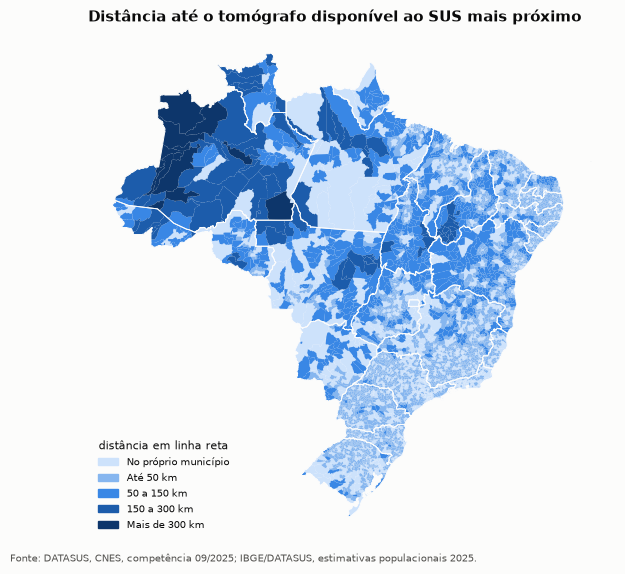

,% de habitantes a mais de 100 km: Mamógrafo,% de habitantes a mais de 100 km: Tomógrafo
regiao,,
Norte,9.5,14.6
Nordeste,0.8,1.1
Centro-Oeste,3.6,2.6
Sudeste,0.0,0.0
Sul,0.0,0.0


In [6]:
dist_tc = desl.distancia_ao_mais_proximo(eq.municipios_com_equipamento_sus("Tomógrafo"))
base.salvar_tabela(dist_tc, "09_distancia_tomografo_sus_municipio")
classes = ["No próprio município", "Até 50 km", "50 a 150 km", "150 a 300 km", "Mais de 300 km"]
fig, ax = g.mapa_municipios(dist_tc.set_index("mun").km_servico_mais_proximo,
                            "Distância até o tomógrafo disponível ao SUS mais próximo", "distância em linha reta",
                            [-0.1, 0.1, 50, 150, 300, 5000], classes)
g.salvar(fig, "09_mapa_distancia_tomografo_sus", FONTE_CNES)
plt.show()
longe = {}
for nome in ["Mamógrafo", "Tomógrafo"]:
    t = desl.distancia_ao_mais_proximo(eq.municipios_com_equipamento_sus(nome))
    longe[nome] = t.groupby("regiao").apply(lambda x: x.habitantes[x.km_servico_mais_proximo > 100].sum()
                                            / x.habitantes.sum() * 100, include_groups=False).round(1)
longe = pd.DataFrame(longe).reindex(c.REGIOES)
base.salvar_tabela(longe, "09_pct_habitantes_mais_100km_equipamento_sus", index=True)
longe.add_prefix("% de habitantes a mais de 100 km: ")

No Sul e no Sudeste, praticamente toda a população está a menos de 100 km de um tomógrafo e de um mamógrafo do SUS. No Norte, 15% da população está a mais de 100 km do tomógrafo mais próximo, e 10% do mamógrafo mais próximo. No mapa, os vazios estão no interior do Amazonas e do Pará, onde as distâncias em linha reta passam de 300 km.

## A oferta cresceu?

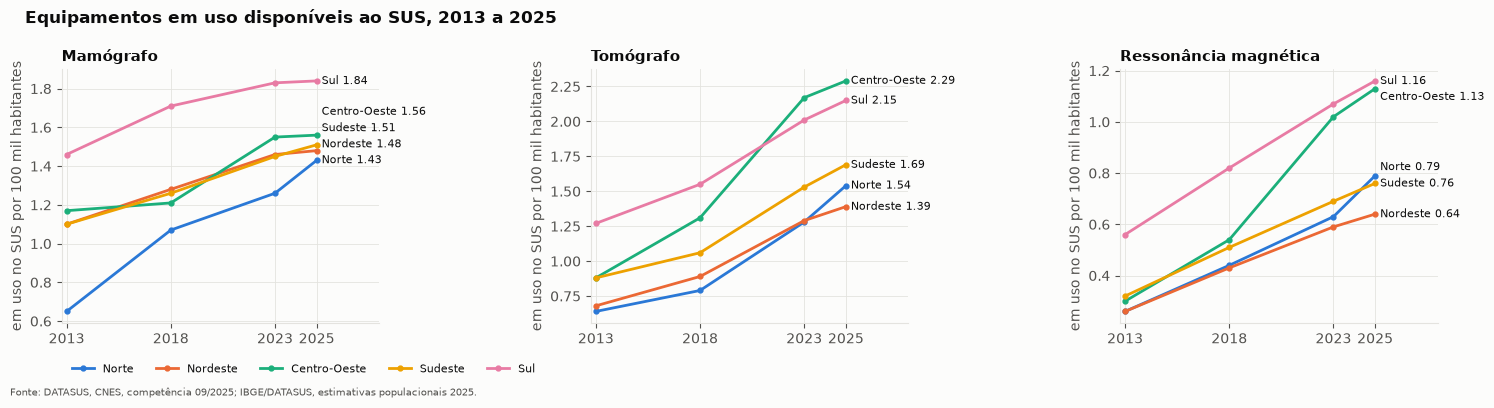

In [7]:
evol = eq.evolucao()
base.salvar_tabela(evol, "09_evolucao_equipamentos_sus")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nome in zip(axes, ["Mamógrafo", "Tomógrafo", "Ressonância magnética"]):
    g.linhas(evol[evol.equipamento == nome], "ano", "em_uso_sus_por_100mil_hab", "regiao", nome,
             "em uso no SUS por 100 mil habitantes", fmt="{:.2f}", ordem=c.REGIOES, ax=ax, legenda=(nome == "Mamógrafo"))
    ax.set_xticks([2013, 2018, 2023, 2025])
fig.suptitle("Equipamentos em uso disponíveis ao SUS, 2013 a 2025", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
g.salvar(fig, "09_evolucao_equipamentos_sus", FONTE_CNES)
plt.show()

A oferta pública de equipamentos cresceu em todas as regiões. O número de tomógrafos do SUS por habitante mais que dobrou no Norte (de 0,64 para 1,54 por 100 mil), e os mamógrafos também cresceram. A distância entre as regiões diminuiu, mas não desapareceu: o Sul continua com mais equipamentos por habitante em todos os tipos.

## Hospitais habilitados em oncologia

Os equipamentos de imagem servem ao diagnóstico. O tratamento do câncer, por sua vez, só pode ser feito no SUS em hospitais habilitados pelo Ministério da Saúde como UNACON (Unidade de Assistência de Alta Complexidade em Oncologia) ou CACON (Centro, que inclui obrigatoriamente radioterapia). O gráfico mostra quantos existem em cada estado.

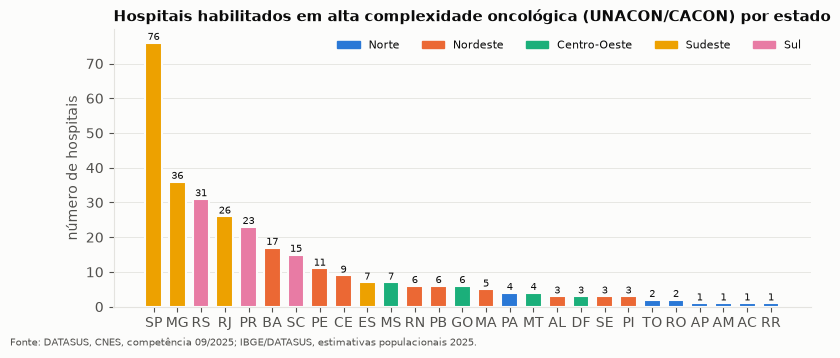

,UNACON/CACON,Radioterapia,Diagnóstico de mama (SDM),unidades_atencao_primaria,unacon_cacon_por_milhao,atencao_primaria_por_100mil
regiao,,,,,,
Norte,12,10,2,4812,1.28,51.4
Nordeste,63,26,13,20392,2.14,69.2
Centro-Oeste,20,10,6,3492,2.29,40.0
Sudeste,145,80,12,15090,3.16,32.9
Sul,69,39,2,7416,4.31,46.3


In [8]:
oferta_uf = rede.oferta_por_uf()
base.salvar_tabela(oferta_uf, "09_oferta_servicos_por_uf")
s = oferta_uf.set_index("uf")["UNACON/CACON"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(s.index, s.values, color=[g.COR_REGIAO[c.SIGLA_PARA_REGIAO[u]] for u in s.index], width=0.7,
       edgecolor=g.SUPERFICIE, linewidth=1.5)
for i, v in enumerate(s.values):
    ax.text(i, v + 0.8, str(v), ha="center", fontsize=7.5)
ax.set(title="Hospitais habilitados em alta complexidade oncológica (UNACON/CACON) por estado",
       ylabel="número de hospitais")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=g.COR_REGIAO[r]) for r in c.REGIOES], labels=c.REGIOES,
          ncol=5, loc="upper right", fontsize=8)
g.salvar(fig, "09_unacon_cacon_por_uf", FONTE_CNES)
plt.show()
oferta_reg = rede.oferta_por_regiao()
base.salvar_tabela(oferta_reg, "09_oferta_servicos_por_regiao", index=True)
oferta_reg[["UNACON/CACON", "Radioterapia", "Diagnóstico de mama (SDM)", "unidades_atencao_primaria",
            "unacon_cacon_por_milhao", "atencao_primaria_por_100mil"]]

O Brasil tem 309 hospitais habilitados em alta complexidade oncológica. Só São Paulo tem 76, mais do que toda a região Nordeste (63) e seis vezes a região Norte inteira (12). Roraima e Amapá têm um hospital cada e nenhum serviço de radioterapia habilitado. Radioterapia é ainda mais concentrada: 165 serviços no país, 80 deles no Sudeste e só 10 no Norte. Por habitante, o Sul tem 4,3 hospitais oncológicos por milhão de mulheres, mais de três vezes o Norte (1,3).

A atenção primária segue o padrão oposto. O Nordeste e o Norte têm mais unidades básicas por habitante do que o Sudeste. Ou seja, a porta de entrada existe em todo o país; o que falta, nas regiões mais pobres, é o que vem depois dela.

## Onde ficam os centros de tratamento

198 municípios têm UNACON/CACON, de 5,570 municípios do país


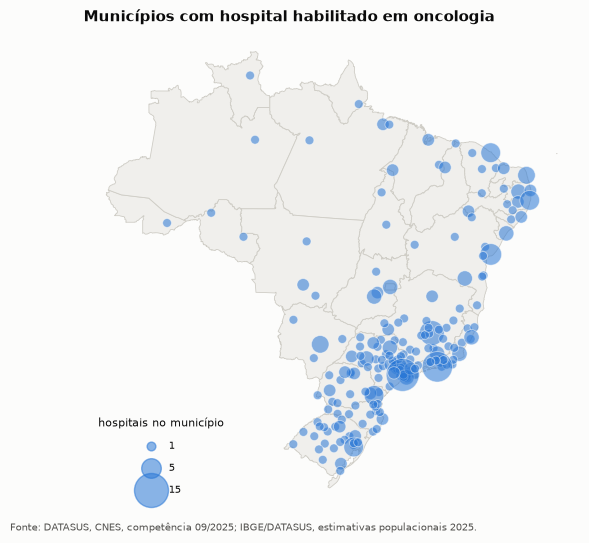

ano,2013,2018,2023,2025
regiao,,,,
Norte,8,11,11,12
Nordeste,45,54,58,63
Centro-Oeste,20,21,19,20
Sudeste,124,134,139,145
Sul,60,66,69,69


In [9]:
mun_serv = rede.municipios_com_servico()
municipios = base.carregar("municipios")
pontos = mun_serv[mun_serv.servico == "UNACON/CACON"].merge(municipios[["mun", "lat", "lon", "nome"]], on="mun")
base.salvar_tabela(pontos, "09_municipios_com_unacon_cacon")
print(f"{len(pontos)} municípios têm UNACON/CACON, de {len(municipios):,} municípios do país")
fig, ax = g.mapa_pontos(pontos, "estabelecimentos", "Municípios com hospital habilitado em oncologia",
                        "hospitais no município", escala=40, legenda_valores=[1, 5, 15])
g.salvar(fig, "09_mapa_centros_oncologia", FONTE_CNES)
plt.show()
evol_serv = rede.evolucao_oferta()
base.salvar_tabela(evol_serv, "09_evolucao_unacon_cacon")
evol_serv.pivot(index="regiao", columns="ano", values="UNACON/CACON").reindex(c.REGIOES)

Apenas 198 dos 5.570 municípios têm hospital habilitado em oncologia, concentrados no litoral e no eixo Sul-Sudeste. O número de hospitais passou de 252 em 2013 para 309 em 2025, um aumento de 23%, enquanto os diagnósticos de câncer de mama no SUS cresceram cerca de 55% no mesmo período. O caderno 10 mostra quanto as pacientes precisam viajar por causa dessa concentração.

## O que levar para o TCC

Só metade dos mamógrafos, tomógrafos e aparelhos de ressonância do país está disponível ao SUS, que atende três quartos da população. Norte e Nordeste têm menos equipamentos por habitante, sobretudo os mais caros, e quase metade da população nordestina vive em municípios sem tomógrafo público. A oferta pública de equipamentos cresceu desde 2013, mas os hospitais oncológicos cresceram menos que a demanda e continuam concentrados no Sul e no Sudeste. Esses vazios de infraestrutura são o argumento central para tecnologias de diagnóstico e acompanhamento que não dependam de grandes equipamentos, como o biossensor proposto no projeto.